In [1]:
import sys
sys.path.append('../')

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import seaborn as sns
import model
import json, csv
import mvpy
import plots

from copy import deepcopy

In [2]:
from typing import Optional

def insert_image(ax, path: str, zoom: float = 0.1, pos: tuple[float, float] = (0.0, 0.0), color: Optional[np.ndarray] = None):
    '''
    '''
    
    # load image
    img = mpimg.imread(path)
    
    # if desired, recolour
    if color is not None:
        img[(img != 0).any(axis = -1)] = color
    
    # make image
    icon = OffsetImage(img, zoom = zoom)
    
    box = AnnotationBbox(
        icon,
        pos,
        xycoords = ax.transAxes,
        frameon = False
    )
    
    # add to axis
    ax.add_artist(box)

def insert_rdm(ax, cm, n_items: int, n_rdms: int, pos: tuple, template: np.ndarray | None = None, noise_level: float = 0.5, size: tuple = (0.2, 0.3), offset_x: float = 0.0125, offset_y: float = -0.025, lw: float = 1.5, lw_i: float = 0.5, upper: bool = False) -> None:
    """
    """
    
    x, y = pos
    w, h = size
    
    for i in range(n_rdms, 0, -1):
        if template is None:
            rdm = np.random.uniform(low = -1, high = 1, size = (n_items, n_items))
            rdm[np.arange(n_items),np.arange(n_items)] = 1.0
        else:
            rdm = template.copy()
            
            noise = noise_level * np.random.uniform(low = -1, high = 1, size = (n_items, n_items))
            tri_x, tri_y = np.triu_indices(rdm.shape[0], k = 1)
            rdm[tri_x,tri_y] += noise[tri_x,tri_y]
            rdm[tri_y,tri_x] += noise[tri_x,tri_y]
            rdm = np.clip(rdm, a_min = -1.0, a_max = 1.0)

        ax_i = ax.inset_axes([x + offset_x * i, y + offset_y * i, w, h])
        ax_i.axis('off')
        
        col = plots.colours.RDM1
        
        if upper:
            tri_x, tri_y = np.tril_indices(rdm.shape[0], k = -1)
            rdm[tri_x,tri_y] = np.nan
        
        ax_i.imshow(rdm, vmin = -1, vmax = 1, cmap = cm)
        
        if upper:
            ax_i.plot([-0.5, n_items - 0.5], [-0.5, -0.5], color = col, linewidth = lw)
            ax_i.plot([n_items - 0.5, n_items - 0.5], [-0.5, n_items - 0.5], color = col, linewidth = lw)
            
            for j in range(n_items):
                ax_i.plot([j - 0.5, n_items - 0.5], [j + 0.5, j + 0.5], color = col, linewidth = lw_i)
                ax_i.plot([j - 0.5, j - 0.5], [j + 0.5, -0.5], color = col, linewidth = lw_i)
                
                # outline
                ax_i.plot([j - 0.5, j + 0.5], [j + 0.5, j + 0.5], color = col, linewidth = lw / 2)
                ax_i.plot([j - 0.5, j - 0.5], [j - 0.5, j + 0.5], color = col, linewidth = lw / 2)
        else:
            ax_i.plot([-0.5, n_items - 0.5], [-0.5, -0.5], color = col, linewidth = lw)
            ax_i.plot([-0.5, n_items - 0.5], [n_items - 0.5, n_items - 0.5], color = col, linewidth = lw)
            ax_i.plot([-0.5, -0.5], [-0.5, n_items - 0.5], color = col, linewidth = lw)
            ax_i.plot([n_items - 0.5, n_items - 0.5], [-0.5, n_items - 0.5], color = col, linewidth = lw)

            for j in range(n_items):
                ax_i.plot([j - 0.5, j - 0.5], [-0.5, n_items - 0.5], color = col, linewidth = lw_i)
                ax_i.plot([-0.5, n_items - 0.5], [j - 0.5, j - 0.5], color = col, linewidth = lw_i)

In [3]:
'''
load config and data
'''

import hydra
from omegaconf import DictConfig, OmegaConf
from loguru import logger
from tqdm import tqdm

from os.path import join
from pathlib import Path
from bids import BIDSLayout

import pandas as pd
import numpy as np
import json, csv

import model

from typing import Tuple, Dict

import os
from hydra import initialize, initialize_config_module, initialize_config_dir, compose
from omegaconf import OmegaConf

# load config
with initialize(version_base=None, config_path="../conf"):
    cfg = compose(config_name = 'config.yaml', overrides = 
                  ['data=exp2', 'run=5', 'device=cpu',
                   'data.path=../data/ds-exp2/',
                   'data.resources=../data/resources/']
    )

# load data
data = model.dataset.Dataset(
    cfg, logger
).load()

# load arrangements
arrangements = data.load_arrangements(n_session = 1)

# set task
task = cfg.task.masubsub

# load demographics
X, L = arrangements.make_demographics(task.demographics, cfg)
X = X.cpu().numpy()

2026-11-18 15:32:12.216 | INFO     | model.dataset:load:1048 - Loading BIDS...
2026-11-18 15:32:12.223 | INFO     | model.dataset:load:1057 - Filtering subjects...


In [4]:
from omegaconf import DictConfig, OmegaConf
from loguru import logger

from os.path import join
from pathlib import Path
from bids import BIDSLayout
from tqdm import tqdm

import math
import pandas as pd
import numpy as np
import torch
import json, csv, hashlib

import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

from mvpy.math import pearsonr, spearmanr
from mvpy.estimators import RidgeEncoder
from mvpy.preprocessing import Scaler
from mvpy.crossvalidation import RepeatedKFold, cross_val_score
from mvpy import metrics as mv_metrics
from sklearn.pipeline import make_pipeline

from model import metrics

from typing import Tuple, Dict, List, Any

do_preprocess = True
do_residualise = True

if True:
    # log progress
    if cfg.verbose:
        logger.info('Performing arrangement subject-subject...')
    
    # get functions
    gram_fn = metrics.get_gram_fn(cfg)
    
    # load multiple arrangement data
    arrangements = data.load_arrangements(n_session = 1)
    
    # check subjects
    n_subjects = torch.unique(arrangements.subject_nos).shape[0]
    
    # check boards
    n_boards = torch.unique(arrangements.board_nos).shape[0]
    
    # check items
    n_items = (
        (arrangements.subject_nos == arrangements.subject_nos[0]) & \
        (arrangements.board_nos == arrangements.board_nos[0])
    ).sum().cpu().item()
    
    # setup board-wise RDMs
    rdm_f = torch.zeros(
        (n_subjects, n_boards, n_items, n_items),
        device = cfg.device
    )
    
    # setup progressbar
    pbar = tqdm(
        total = n_subjects * n_boards,
        leave = True,
        disable = (cfg.verbose == False)
    )
    
    # iterate over subjects
    for i, subject_i in enumerate(torch.unique(arrangements.subject_ids)):
        # make board id placeholder
        is_first = True
        
        # iterate over boards
        for j, board_i in enumerate(torch.unique(arrangements.board_nos)):
            # create mask
            mask_ij = (arrangements.subject_ids == subject_i) & \
                      (arrangements.board_nos == board_i)
            
            # grab board identity
            board_idx = arrangements.board_ids[mask_ij][0].cpu().item()
            board_idx = board_idx + 1 if ((board_idx == 13) and (not is_first)) else board_idx
            is_first = False if board_idx == 13 else is_first
            
            # prepare behavioural data
            order = arrangements.word_nos[mask_ij].argsort()
            pos_ij = arrangements.positions[mask_ij][order,:]
            
            # make gram matrices
            kwargs = {} if cfg.metrics.gram != 'euclidean' else {'norm': False}
            rdm_f[i,board_idx] = gram_fn(pos_ij, **kwargs)
            
            # update tally
            pbar.update(1)
    
    # make sure tally is closed
    pbar.close()
    
    # setup preprocessing
    from mvpy.math import rank
    preprocess = Scaler().to_torch()
    
    tri_x, tri_y = torch.triu_indices(
        n_items, n_items,
        offset = 1
    )
    
    pre_f = torch.zeros(
        (n_boards, tri_x.shape[0], n_subjects),
        device = cfg.device
    )
    
    for i, subject_i in enumerate(torch.unique(arrangements.subject_ids)):
        if do_preprocess:
            pre_f[:,:,i] = preprocess.fit_transform(
                rank(
                    rdm_f[i,:,tri_x,tri_y]
                ).T
            ).T
        else:
            pre_f[:,:,i] = rdm_f[i,:,tri_x,tri_y]
    
    # setup residualiser
    residualise = make_pipeline(
        RidgeEncoder(
            alphas = torch.tensor([1e-5], device = cfg.device)
        )
    )
    
    # setup data structure
    res_f = torch.zeros(
        (n_boards, tri_x.shape[0], n_subjects),
        device = cfg.device
    )
    
    res_ß = torch.zeros(
        (n_subjects, n_boards),
        device = cfg.device
    )
    
    # residualise rdms
    for i, subject_i in enumerate(torch.unique(arrangements.subject_ids)):
        # setup mask
        not_i = torch.arange(n_subjects, device = cfg.device) != i
        
        # make templates
        X_i = pre_f[:,:,not_i].mean(-1)
        
        # setup data
        X_h = []
        ß_i = []
        
        # iterate over boards
        for j in range(n_boards):
            # compute fit
            y_ij = pre_f[j,:,i]
            residualise.fit(X_i[j][:,None], y_ij)
            
            # residualise
            if do_residualise:
                X_h.append(y_ij - residualise.predict(X_i[j][:,None]).squeeze())
            else:
                X_h.append(y_ij)
            ß_i.append(residualise[-1].coef_.clone().squeeze())

        # stack
        res_f[:,:,i] = torch.stack(X_h, dim = 0)
        res_ß[i,:] = torch.stack(ß_i, dim = 0)
    
    # setup data structure
    out_f = torch.zeros(
        (n_boards, n_subjects, n_subjects),
        device = cfg.device
    )
    
    # compute similarities
    for i in range(n_subjects):
        for j in range(i, n_subjects):
            out_f[:,j,i] = out_f[:,i,j] = spearmanr(res_f[:,:,i], res_f[:,:,j])
    
    # prepare data
    X, L = arrangements.make_demographics(task.demographics, cfg)
    X = X
    y = out_f.mean(0)
    tri_x, tri_y = torch.triu_indices(n_subjects, n_subjects, offset = 1)

2026-11-18 15:32:22.587 | INFO     | __main__:<module>:36 - Performing arrangement subject-subject...
100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4545/4545 [00:03<00:00, 1210.89it/s]


In [5]:
y.shape

torch.Size([303, 303])

In [6]:
res_f.shape

torch.Size([15, 190, 303])

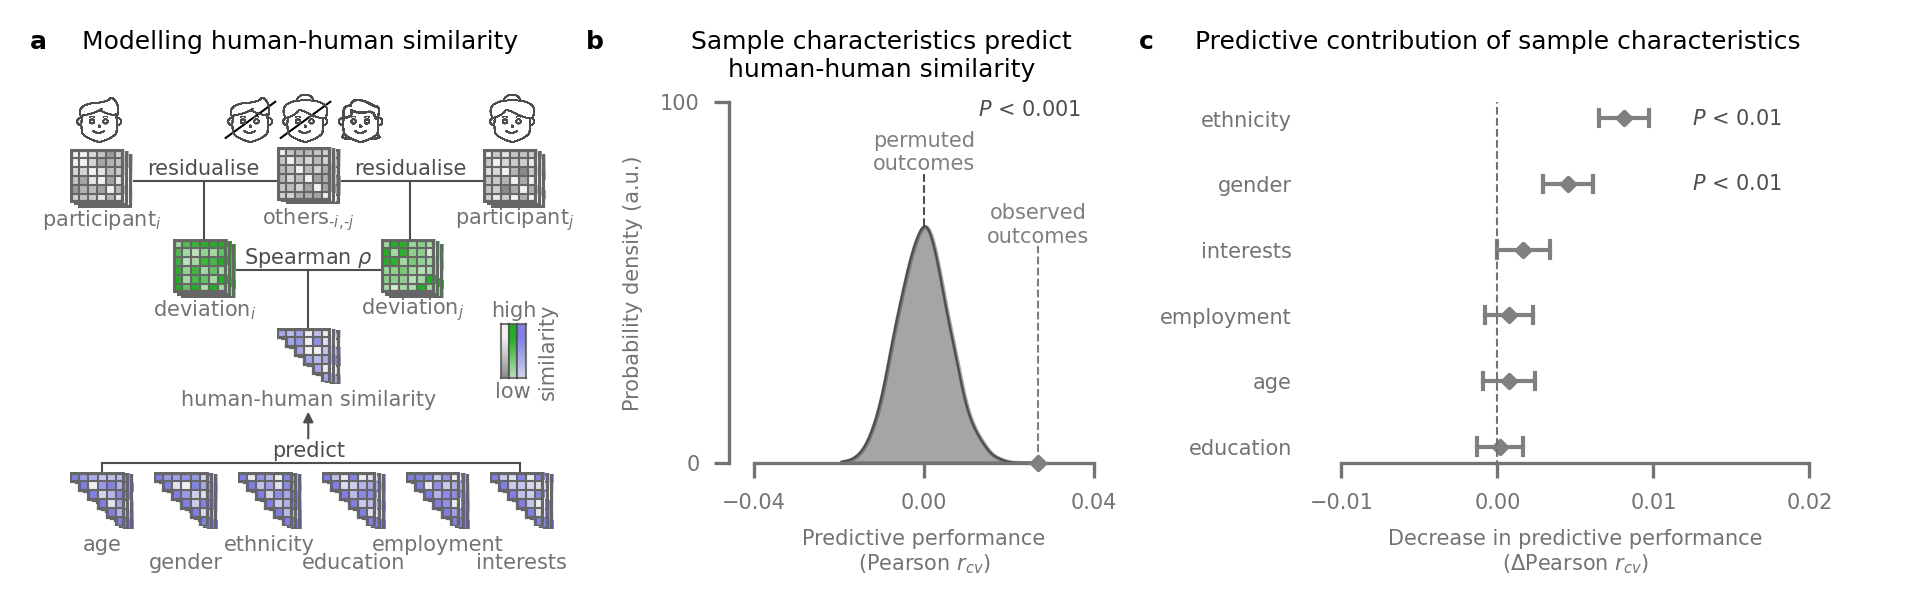

In [13]:
from matplotlib.colors import LinearSegmentedColormap

hypothesis_test = 'sign'
hypothesis_alternative = 'two-sided'
hypothesis_method = 'holm'
hypothesis_se = 'within'

hypothesis_test2 = 'permutation'
hypothesis_alternative2 = 'greater'
hypothesis_method2 = 'holm'
hypothesis_se2 = 'within'

run = 0
exp = 2
mod = 'glove'

run_dem = 5
order_importance = True
order_dem = [5, 3, 4, 1, 0, 2]

cols = np.array([
    plots.colours.HL_EMBEDDING,
    plots.colours.HL_OTHERS,
    plots.colours.HL_SELF
])

cols2 = np.array([
    plots.colours.CM_RDM_CL(0.00),
    plots.colours.CM_RDM_CL(0.20),
    plots.colours.CM_RDM_CL(0.40)
])

CM_RDM_HL = LinearSegmentedColormap.from_list(
    'rdm_hl',
    [plots.colours.RDM2, plots.colours.HL_SELF]
)

HL_INTER = np.array([0.50, 0.50, 0.90, 1.0])

CM_RDM_HL_BL = LinearSegmentedColormap.from_list(
    'rdm_hl_bl',
    [plots.colours.RDM2, HL_INTER]
)

# initialise plot
fig, ax = plt.subplots(figsize = (6.4, 2.0), dpi = 300)
ax.axis('off')

# setup base canvases
ax1 = ax.inset_axes([0.0, 0.10, 0.30, 0.80])
ax2 = ax.inset_axes([0.375, 0.10, 0.185, 0.80])
ax3 = ax.inset_axes([0.695, 0.10, 0.255, 0.80])

'''
precompute deltas;
these are also required for ordering demographics
'''

out = torch.load(f'../data/ds-exp{exp}/derivatives/run-00{run_dem}/tasks/task-masubsub_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))

full = out['r_full'][None,:].cpu().numpy()
perm = out['r_base'][None,:].cpu().numpy()
block = out['r_perm'].cpu().numpy().T

desc_full = model.stats.sample_descriptives(full.T, se = hypothesis_se2)
stat_full = model.stats.sample_tests(
    full.mean() - perm,
    test = hypothesis_test2, alternative = hypothesis_alternative2, 
    method = hypothesis_method2, se = hypothesis_se2
)

model.stats.save_results(desc_full, './deliverable/csv/fig4/all_wthn_desc.csv')
model.stats.save_results(stat_full, './deliverable/csv/fig4/all_wthn_block.csv')

desc_block = model.stats.sample_descriptives((full.mean() - block).T, se = hypothesis_se2)
stat_block = model.stats.sample_tests(
    full.mean() - block,
    test = hypothesis_test2, alternative = hypothesis_alternative2, 
    method = hypothesis_method2, se = hypothesis_se2
)

model.stats.save_results(desc_block, './deliverable/csv/fig4/all_wthn_desc-2.csv')
model.stats.save_results(stat_block, './deliverable/csv/fig4/all_wthn_block-2.csv')

delta = full.mean() - block
labels_D = list(out['labels'].keys())

if order_importance:
    order = delta.mean(1).argsort()
    labels_D = np.array(labels_D)[order].tolist()
else:
    order = np.arange(block.shape[0])

'''
panel c + d
'''

# full model
from sklearn.neighbors import KernelDensity
perm_pad = 0.0
kde = KernelDensity(bandwidth = 0.0015).fit(perm.T)
x_i = np.linspace(perm.min() - perm_pad, perm.max() + perm_pad, 100)
scores = kde.score_samples(x_i[:,None])
scores = np.exp(scores)
scores = scores / np.trapezoid(scores, x_i)

min_p = stat_full[0]['p_cor']
rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'

ax2.plot(x_i, scores, color = plots.colours.H2, linewidth = 0.5)
ax2.fill_between(x_i, scores, color = plots.colours.H2, alpha = 0.5)
ax2.plot([full.mean(), full.mean()], [0.0, 60.0], color = cols[1], linewidth = 0.5, linestyle = '--')
ax2.scatter([full.mean()], [0.0], marker = 'D', s = 5, color = cols[1], clip_on = False, zorder = 5)
ax2.annotate('observed\noutcomes', xy = (0, 0), xytext = (full.mean(), 60.0), ha = 'center', va = 'bottom', color = cols[1], fontsize = 5)

ax2.plot([perm.mean(), perm.mean()], [scores.max(), 80.0], color = plots.colours.H2, linewidth = 0.5, linestyle = '--')
ax2.annotate('permuted\noutcomes', xy = (0, 0), xytext = (perm.mean(), 80.0), ha = 'center', va = 'bottom', color = cols[1], fontsize = 5)

ax2.annotate(f'{rep_p}', xy = (0, 0), xytext = (0.025, 95.0), ha = 'center', va = 'bottom', color = plots.colours.H2, fontsize = 5)

ax2.set_xlim([-0.04, 0.04])
ax2.set_xticks([-0.04, 0.0, 0.04])
ax2.set_xlabel('Predictive performance\n' + fr'(Pearson $r_{{cv}}$)', fontsize = 5)
ax2.set_ylim([0.0, 100.0])
ax2.set_yticks([0, 100])
ax2.set_ylabel(fr'Probability density (a.u.)', fontsize = 5)

sns.despine(ax = ax2)
ax2.spines['left'].set_position(('axes', -0.075))

# individual blocks
order_importance = True
bar_size = 0.125
bar_ci = 1.96
lw = 1.0

min_p = 1.0
    
for ii, i in enumerate(order[::-1]):
    mu = delta[i].mean()
    se = np.std(delta[i])
    
    ii = block.shape[0] - ii - 1
    xs, xe = ii - bar_size, ii + bar_size
    
    pval = stat_block[i]['p_cor']
    min_p = pval
    rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'
    if pval <= 0.05:
        ax3.annotate(f'{rep_p}', xy = (0, 0), xytext = (0.0125, ii), ha = 'left', va = 'center', color = plots.colours.H2, fontsize = 5)

    color = cols[1]
    bar_col = cols[1]
    
    ax3.plot([mu - bar_ci * se, mu + bar_ci * se], [ii, ii], color = bar_col, linewidth = lw, zorder = 1)
    ax3.plot([mu - bar_ci * se, mu - bar_ci * se], [ii - bar_size, ii + bar_size], color = bar_col, linewidth = lw, zorder = 1)
    ax3.plot([mu + bar_ci * se, mu + bar_ci * se], [ii - bar_size, ii + bar_size], color = bar_col, linewidth = lw, zorder = 1)
    ax3.scatter([mu], [ii], color = color, marker = 'D', s = 5, zorder = 2)

ax3.plot([0, 0], [-0.5, 5.5], color = plots.colours.H3, linewidth = 0.5, linestyle = '--')

ax3.set_ylim([-0.25, 5.25])
ax3.set_xlim([-0.01, 0.02])
ax3.set_yticks(np.arange(delta.shape[0]), labels = labels_D, fontsize = 5)
ax3.set_xticks(np.arange(-0.01, 0.021, 0.01))

ax3.set_xlabel('Decrease in predictive performance\n' + fr'($\Delta$Pearson $r_{{cv}}$)', fontsize = 5)

sns.despine(ax = ax3)
ax3.spines['left'].set_position(('axes', -0.075))
ax3.spines['left'].set_visible(False)
ax3.tick_params(axis = 'y', which = 'both', length = 0)

ax3.tick_params(axis = 'both', which = 'both', labelsize = 5)
ax3.xaxis.label.set_fontsize(5)
ax3.yaxis.label.set_fontsize(5)

ax2.tick_params(axis = 'both', which = 'both', labelsize = 5)
ax2.xaxis.label.set_fontsize(5)
ax2.yaxis.label.set_fontsize(5)
    
'''
panel A
'''

ax1.set_xlim([0, 1])
ax1.set_ylim([0, 1])
ax1.axis('off')

tri_x, tri_y = np.triu_indices(20, k = 1)

subject0, subject1 = 1, 2

rdm_0 = 1 - rdm_f[subject0,-1,0:6,0:6].detach().cpu().numpy()
rdm_e0 = 1 - rdm_f[subject1+1:,-1,0:6,0:6].detach().cpu().numpy().mean(0)
rdm_r0 = np.zeros((20, 20))
rdm_r0[tri_x,tri_y] = 1 - res_f[0,:,subject0].detach().cpu().numpy()
rdm_r0[tri_y,tri_x] = 1 - res_f[0,:,subject0].detach().cpu().numpy()
rdm_r0 = rdm_r0[0:6,0:6]
rdm_r0 = rdm_r0 - 0.5
vmax = max(np.abs(rdm_r0.min()), np.abs(rdm_r0.max()))
rdm_r0 = rdm_r0 / vmax

rdm_1 = 1 - rdm_f[subject1,-1,0:6,0:6].detach().cpu().numpy()
rdm_e1 = 1 - rdm_f[subject1+1:,-1,0:6,0:6].detach().cpu().numpy().mean(0)
rdm_r1 = np.zeros((20, 20))
rdm_r1[tri_x,tri_y] = 1 - res_f[0,:,subject1].detach().cpu().numpy()
rdm_r1[tri_y,tri_x] = 1 - res_f[0,:,subject1].detach().cpu().numpy()
rdm_r1 = rdm_r1[0:6,0:6]
rdm_r1 = rdm_r1 - 0.5
vmax = max(np.abs(rdm_r1.min()), np.abs(rdm_r1.max()))
rdm_r1 = rdm_r1 / vmax

rdm_args = dict(
    size = (0.0984, 0.1546),
    offset_x = 0.007,
    offset_y = -0.007
)

# subject left
insert_image(ax1, './resources/human-1.png', 0.045, (0.06, 0.95), color = plots.colours.H2)

insert_rdm(
    ax1, 
    plots.colours.CM_RDM_CL, 
    6, 
    3, 
    (0.00, 0.725), 
    template = rdm_0, 
    **rdm_args
)

insert_rdm(
    ax1, 
    CM_RDM_HL, 
    6, 
    3, 
    (0.1875, 0.475), 
    template = rdm_r0, 
    **rdm_args
)

# subject right
insert_image(ax1, './resources/human-2.png', 0.045, (0.81, 0.95), color = plots.colours.H2)

insert_rdm(
    ax1, 
    plots.colours.CM_RDM_CL, 
    6, 
    3, 
    (0.75, 0.725), 
    template = rdm_1, 
    **rdm_args
)

insert_rdm(
    ax1, 
    CM_RDM_HL, 
    6, 
    3, 
    (0.565, 0.475), 
    template = rdm_r1, 
    **rdm_args
)

# big RDM
rdm_args['offset_x'] = 0.008
rdm_args['offset_y'] = -0.003

show_n = 6
rdmf = out_f.mean(0)[0:show_n,:][:,0:show_n].detach().cpu().numpy()
rdmf = np.clip(40 * rdmf, a_min = -1, a_max = 1)
rdmf = rdmf - 0.5
vmax = max(np.abs(rdmf.min()), np.abs(rdmf.max()))
rdmf = rdmf / vmax

insert_rdm(
    ax1, 
    CM_RDM_HL_BL, 
    show_n, 
    3, 
    (0.375, 0.225), 
    template = rdmf, 
    upper = True,
    **rdm_args
)

# middle
insert_image(ax1, './resources/human-1.png', 0.045, (0.335, 0.95), color = plots.colours.H2)
insert_image(ax1, './resources/human-2.png', 0.045, (0.435, 0.95), color = plots.colours.H2)
insert_image(ax1, './resources/human-3.png', 0.045, (0.535, 0.95), color = plots.colours.H2)
ax1.plot([0.290, 0.380], [0.90, 1.0], color = 'black', clip_on = False, lw = 0.5)
ax1.plot([0.390, 0.480], [0.90, 1.0], color = 'black', clip_on = False, lw = 0.5)

insert_rdm(
    ax1, 
    plots.colours.CM_RDM_CL, 
    6, 
    3, 
    (0.375, 0.725), 
    template = rdm_e0, 
    **rdm_args
)

# annotations
anno_arg = dict(
    xy = (0, 0),
    fontsize = 5,
    color = plots.colours.H2,
    ha = 'center',
    va = 'center'
)

ax1.annotate(
    'residualise',
    xytext = (0.25, 0.815),
    **anno_arg
)

ax1.annotate(
    'residualise',
    xytext = (0.625, 0.815),
    **anno_arg
)

ax1.annotate(
    fr'Spearman $\rho$',
    xytext = (0.44, 0.57),
    **anno_arg
)

line_arg = dict(
    color = plots.colours.H2,
    lw = 0.5
)

ax1.plot([0.10, 0.40], [0.78, 0.78], **line_arg) # left
ax1.plot([0.25, 0.25], [0.60, 0.78], **line_arg) # left

ax1.plot([0.475, 0.775], [0.78, 0.78], **line_arg) # right
ax1.plot([0.625, 0.625], [0.60, 0.78], **line_arg) # right

ax1.plot([0.29, 0.59], [0.535, 0.535], **line_arg) # middle
ax1.plot([0.44, 0.44], [0.35, 0.535], **line_arg) # middle

# labels
anno_arg2 = dict(
    xy = (0, 0),
    fontsize = 5,
    color = plots.colours.H3,
    ha = 'center',
    va = 'center'
)

ax1.annotate(
    fr'participant$_i$',
    xytext = (0.065, 0.675),
    **anno_arg2
)

ax1.annotate(
    fr'others$_{{\text{{-}}i,\!\text{{-}}j}}$',
    xytext = (0.440, 0.675),
    **anno_arg2
)

ax1.annotate(
    fr'participant$_j$',
    xytext = (0.815, 0.675),
    **anno_arg2
)

ax1.annotate(
    fr'deviation$_i$',
    xytext = (0.2525, 0.425),
    **anno_arg2
)

ax1.annotate(
    fr'deviation$_j$',
    xytext = (0.630, 0.425),
    **anno_arg2
)

ax1.annotate(
    fr'human-human similarity',
    xytext = (0.440, 0.175),
    **anno_arg2
)

# predictors
keys = list(L.keys())
w_h = 0.1525
order = [0, 1, 2, 3, 4, 5]

for i, ii in enumerate(order):
    key = keys[ii]
    
    # grab data
    X_i = X[0:show_n,:][:,0:show_n][...,ii].detach().cpu().numpy()
    
    # preprocess
    if i == 0:
        X_i = 2 * (X_i / X_i.max()) - 1.0
    else:
        X_i = 2 * (X_i - 0.5)
    
    # show data
    w = w_h * i
    ya = -0.175# if i % 2 == 0 else -0.125
    yt = -0.225 if i % 2 == 0 else -0.275#0.0
    
    insert_rdm(
        ax1,
        CM_RDM_HL_BL,
        6, 3,
        (w, ya),
        **rdm_args,
        upper = True
    )
    
    # label data
    ax1.annotate(
        key,
        xytext = (w + 0.065, yt),
        **anno_arg2
    )

line_arg['clip_on'] = False

ax1.annotate(
    'predict',
    xytext = (0.440, 0.035),
    **anno_arg
)

ax1.plot(
    [0.065, 0.825],
    [0.00, 0.00],
    **line_arg
)

ax1.plot(
    [0.065, 0.065],
    [-0.05, 0.000],
    **line_arg
)

ax1.plot(
    [0.825, 0.825],
    [-0.05, 0.000],
    **line_arg
)

ax1.annotate(
    '',
    xytext = (0.440, 0.045),
    xy = (0.440, 0.165),
    ha = 'center',
    va = 'center',
    fontsize = 5,
    arrowprops = dict(
        arrowstyle = '-|>',
        color = plots.colours.H2,
        lw = 0.5
    )
)

# color maps
cm = ax1.inset_axes([0.790, 0.235, 0.015, 0.15])
cn = ax1.inset_axes([0.805, 0.235, 0.015, 0.15])
co = ax1.inset_axes([0.820, 0.235, 0.015, 0.15])

outline_arg = dict(
    color = plots.colours.H2,
    alpha = 0.75,
    clip_on = False,
    lw = 0.5,
    ls = '-'
)

partial_borders = False

for i, ax_i in enumerate([cm, cn, co]):
    ax_i.set_xlim([0, 1])
    ax_i.set_ylim([0, 1])
    ax_i.axis('off')
    
    # top bottom
    ax_i.plot([0, 1], [0, 0], **outline_arg)
    ax_i.plot([0, 1], [1, 1], **outline_arg)
    
    # left right
    if (partial_borders == False) or (i == 2):
        ax_i.plot([1, 1], [0, 1], **outline_arg)
    
    if (partial_borders == False) or (i == 0):
        ax_i.plot([0, 0], [0, 1], **outline_arg)

x = np.linspace(0, 1, 100)
y = np.linspace(0, 1, 100)
z = np.linspace(0, 1, 100)

cm.scatter(x, y, c = z, cmap = plots.colours.CM_RDM_CL)
cn.scatter(x, y, c = z, cmap = CM_RDM_HL)
co.scatter(x, y, c = z, cmap = CM_RDM_HL_BL)

co.annotate('similarity', xy = (0, 0), xytext = (2.5, 0.5), ha = 'left', va = 'center', fontsize = 5, color = plots.colours.H3, rotation = 90)
cn.annotate('low', xy = (0, 0), xytext = (0.5, -0.25), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H3, rotation = 0)
cn.annotate('high', xy = (0, 0), xytext = (0.5, 1.25), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H3, rotation = 0)

'''
cosmetics
'''

# colors
for ax_i in [ax1, ax2, ax3]:
    ax_i.yaxis.label.set_color(plots.colours.H3)
    ax_i.xaxis.label.set_color(plots.colours.H3)
    ax_i.tick_params(axis = 'x', colors = plots.colours.H3)
    ax_i.tick_params(axis = 'y', which = 'minor', colors = plots.colours.H3)
    ax_i.tick_params(axis = 'y', which = 'major', colors = plots.colours.H3)
    ax_i.spines['bottom'].set_color(plots.colours.H3)
    ax_i.spines['left'].set_color(plots.colours.H3)

# labels
ax1.annotate('a', xy = (0, 0), xytext = (-0.05, 1.20), ha = 'center', va = 'top', fontsize = 6, fontweight = 'bold', annotation_clip = False)
ax1.annotate('Modelling human-human similarity', xy = (0, 0), xytext = (0.425, 1.20), ha = 'center', va = 'top', fontsize = 6, annotation_clip = False)

ax2.annotate('b', xy = (0, 0), xytext = (-0.0775, 120.0), ha = 'center', va = 'top', fontsize = 6, fontweight = 'bold', annotation_clip = False)
ax2.annotate('Sample characteristics predict\nhuman-human similarity', xy = (0, 0), xytext = (-0.01, 120.0), ha = 'center', va = 'top', fontsize = 6, annotation_clip = False)

ax3.annotate('c', xy = (0, 0), xytext = (-0.0225, 6.35), ha = 'center', va = 'top', fontsize = 6, fontweight = 'bold', annotation_clip = False)
ax3.annotate('Predictive contribution of sample characteristics', xy = (0, 0), xytext = (0.00, 6.35), ha = 'center', va = 'top', fontsize = 6, annotation_clip = False)

fig.tight_layout()

fig.savefig('./deliverable/png/fig4.png', dpi = 900, format = 'png')
fig.savefig('./deliverable/pdf/fig4.pdf', dpi = 900, format = 'pdf')
fig.savefig('./deliverable/svg/fig4.svg', dpi = 900, format = 'svg')

In [11]:
#grab estimated ceiling
ceil = out['r_ceil']
ceil.mean(), 1.96 * ceil.std()

(tensor(0.5128), tensor(0.0148))